# Complexité empirique de v1CLD (DP)

Benchmark du temps de calcul par itération de sous-gradient pour `MKPCLDProblemDP` sur les instances Pisinger (weakly correlated, α=0.5).

**Variables étudiées :** n (items), m (contraintes), N (scénarios)

In [8]:
# ── Paramètres ────────────────────────────────────────────────────────────────
N_VALUES  = [5, 10, 20, 30, 50]          # valeurs de n (items)
M_VALUES  = [2, 5, 10]                   # valeurs de m (contraintes)
S_VALUES  = [50, 100, 500, 1000]         # valeurs de N (scénarios)

EPSILON   = 0.10
T_ITER    = 1     # itérations par appel chronométré
T_REPS    = 15    # répétitions pour le chrono (moyenne)
T_WARMUP  = 3     # warmup avant chrono

DATASET_DIR = 'data/knapsack/datasets-pisinger'
SEED        = 42
S_BENCH     = 100   # taille de scénarios utilisée pour le benchmark principal

In [9]:
import os, sys, time, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

try:
    ROOT = os.path.dirname(os.path.abspath(__vsc_ipynb_file__))
except NameError:
    ROOT = os.getcwd()

sys.path.insert(0, os.path.join(ROOT, 'lib'))
import v1ld_generic_cpp as cpp

def load_song(filepath, replication=0):
    rows = []
    with open(filepath) as f:
        for line in f:
            v = list(map(float, line.strip().split(',')))
            if int(v[4]) != replication: continue
            m, n = int(v[2]), int(v[3])
            A = np.array(v[5:5+m*n]).reshape(m, n)
            b = np.array(v[5+m*n:5+m*n+m])
            c = np.array(v[5+m*n+m:5+m*n+m+n])
            rows.append((A, b, c))
    N = len(rows)
    assert N > 0, f'Aucun scénario dans {filepath}'
    return rows[0][2], np.ones(N)/N, np.stack([r[0] for r in rows]), np.stack([r[1] for r in rows])

def chrono(prob_class, c, p, A, b, epsilon, t_reps, t_warmup):
    prob = prob_class(c, p, A, b, epsilon)
    for _ in range(t_warmup):
        cpp.solve_v1cld(prob, T=T_ITER, log_interval=0)
    times = []
    for _ in range(t_reps):
        t0 = time.perf_counter()
        cpp.solve_v1cld(prob, T=T_ITER, log_interval=0)
        times.append((time.perf_counter() - t0) * 1000)
    return np.mean(times), np.std(times)

print(f'Module : {cpp.__file__}')

Module : /Users/roman.lendormy/Documents/Cours/X25 - 3A/Stage/Learning_bounds_CCCP/lib/v1ld_generic_cpp.cpython-311-darwin.so


## 1. Collecte des mesures

Pour chaque (n, m) avec N=S_BENCH scénarios, on mesure le temps/itération du DP.

In [10]:
records = []

for n in N_VALUES:
    for m in M_VALUES:
        fname = f'ccmk-song-pisinger-n{n}-m{m}-a50-we-r{SEED}-S{S_BENCH}.txt'
        fpath = os.path.join(ROOT, DATASET_DIR, fname)
        if not os.path.exists(fpath):
            print(f'MANQUANT : {fname}'); continue

        c, p, A, b = load_song(fpath)
        N_scen = len(p)
        W_max  = int(b.max())

        ms_dp, std_dp = chrono(cpp.MKPCLDProblemDP, c, p, A, b, EPSILON, T_REPS, T_WARMUP)

        records.append(dict(n=n, m=m, N=N_scen, W_max=W_max, ms=ms_dp, std=std_dp))
        print(f'n={n:3d} m={m:2d} N={N_scen:4d} W={W_max:6d}  DP={ms_dp:.3f}±{std_dp:.3f} ms')

df = pd.DataFrame(records)
print(f'\n{len(df)} combinaisons mesurées.')

n=  5 m= 2 N= 100 W=  1196  DP=1.453±0.464 ms
n=  5 m= 5 N= 100 W=  1859  DP=3.350±0.669 ms
n=  5 m=10 N= 100 W=  1884  DP=7.864±1.579 ms
n= 10 m= 2 N= 100 W=  3220  DP=5.464±1.064 ms
n= 10 m= 5 N= 100 W=  3220  DP=14.762±2.143 ms
n= 10 m=10 N= 100 W=  3220  DP=28.434±2.842 ms
n= 20 m= 2 N= 100 W=  5386  DP=23.293±1.282 ms
n= 20 m= 5 N= 100 W=  5537  DP=57.725±9.002 ms
n= 20 m=10 N= 100 W=  5537  DP=129.701±20.844 ms
n= 30 m= 2 N= 100 W=  8198  DP=57.359±4.937 ms
n= 30 m= 5 N= 100 W=  8198  DP=123.378±7.234 ms
n= 30 m=10 N= 100 W=  8198  DP=249.708±17.452 ms
n= 50 m= 2 N= 100 W= 13544  DP=158.964±33.274 ms
n= 50 m= 5 N= 100 W= 13544  DP=336.365±11.625 ms
n= 50 m=10 N= 100 W= 13544  DP=678.782±24.309 ms

15 combinaisons mesurées.


## 2. Effet de n

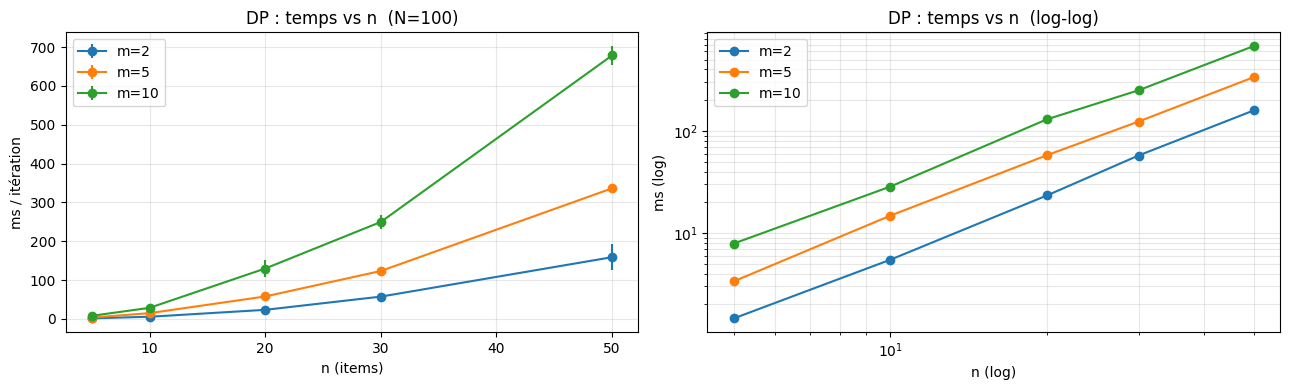

Exposants empiriques en n (pente log-log) :
  m=2 : pente = 2.05  (O(n²) → pente ~2)
  m=5 : pente = 1.99  (O(n²) → pente ~2)
  m=10 : pente = 1.95  (O(n²) → pente ~2)


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
colors = ['tab:blue', 'tab:orange', 'tab:green']

for m_val, color in zip(M_VALUES, colors):
    sub = df[df.m == m_val].sort_values('n')
    if sub.empty: continue
    axes[0].errorbar(sub.n, sub.ms, yerr=sub['std'], marker='o',
                     label=f'm={m_val}', color=color)
    axes[1].plot(sub.n, sub.ms, 'o-', label=f'm={m_val}', color=color)

axes[0].set_xlabel('n (items)'); axes[0].set_ylabel('ms / itération')
axes[0].set_title(f'DP : temps vs n  (N={S_BENCH})')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_xlabel('n (log)'); axes[1].set_ylabel('ms (log)')
axes[1].set_title('DP : temps vs n  (log-log)')
axes[1].legend(); axes[1].grid(True, alpha=0.3, which='both')

plt.tight_layout(); plt.show()

print('Exposants empiriques en n (pente log-log) :')
for m_val in M_VALUES:
    sub = df[df.m == m_val].sort_values('n')
    if len(sub) < 3: continue
    slope = np.polyfit(np.log(sub.n.values.astype(float)),
                       np.log(sub.ms.values), 1)[0]
    print(f'  m={m_val} : pente = {slope:.2f}  (O(n²) → pente ~2)')

## 3. Effet de m

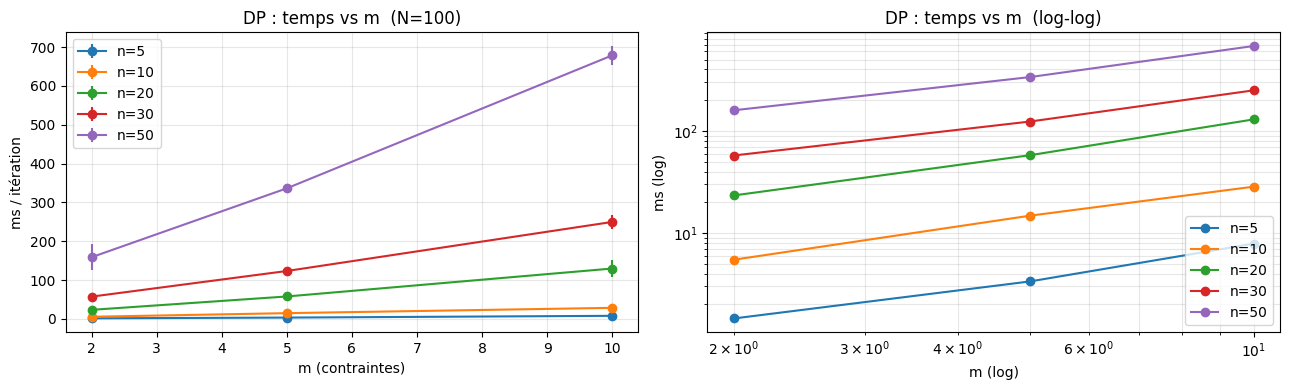

Exposants empiriques en m (pente log-log) :
  n=5 : pente = 1.04  (théorie: ~1)
  n=10 : pente = 1.03  (théorie: ~1)
  n=20 : pente = 1.06  (théorie: ~1)
  n=30 : pente = 0.91  (théorie: ~1)
  n=50 : pente = 0.90  (théorie: ~1)


In [12]:
colors5 = ['tab:blue','tab:orange','tab:green','tab:red','tab:purple']
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for n_val, color in zip(N_VALUES, colors5):
    sub = df[df.n == n_val].sort_values('m')
    if sub.empty: continue
    axes[0].errorbar(sub.m, sub.ms, yerr=sub['std'], marker='o',
                     label=f'n={n_val}', color=color)
    axes[1].plot(sub.m, sub.ms, 'o-', label=f'n={n_val}', color=color)

axes[0].set_xlabel('m (contraintes)'); axes[0].set_ylabel('ms / itération')
axes[0].set_title(f'DP : temps vs m  (N={S_BENCH})')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_xlabel('m (log)'); axes[1].set_ylabel('ms (log)')
axes[1].set_title('DP : temps vs m  (log-log)')
axes[1].legend(); axes[1].grid(True, alpha=0.3, which='both')

plt.tight_layout(); plt.show()

print('Exposants empiriques en m (pente log-log) :')
for n_val in N_VALUES:
    sub = df[df.n == n_val].sort_values('m')
    if len(sub) < 3: continue
    slope = np.polyfit(np.log(sub.m.values.astype(float)),
                       np.log(sub.ms.values), 1)[0]
    print(f'  n={n_val} : pente = {slope:.2f}  (théorie: ~1)')

## 4. Effet de N (scénarios)

In [ ]:
N_FIX, M_FIX = 20, 5

records_s = []
for S in S_VALUES:
    fname = f'ccmk-song-pisinger-n{N_FIX}-m{M_FIX}-a50-we-r{SEED}-S{S}.txt'
    fpath = os.path.join(ROOT, DATASET_DIR, fname)
    if not os.path.exists(fpath): continue
    c, p, A, b = load_song(fpath)
    ms_dp, std_dp = chrono(cpp.MKPCLDProblemDP, c, p, A, b, EPSILON, T_REPS, T_WARMUP)
    records_s.append(dict(S=S, ms=ms_dp, std=std_dp))
    print(f'N={S:5d}  DP={ms_dp:.3f}±{std_dp:.3f} ms')

df_s = pd.DataFrame(records_s)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].errorbar(df_s.S, df_s.ms, yerr=df_s['std'], marker='o')
axes[0].set_xlabel('N (scénarios)'); axes[0].set_ylabel('ms / itération')
axes[0].set_title(f'DP : temps vs N  (n={N_FIX}, m={M_FIX})')
axes[0].grid(True, alpha=0.3)

axes[1].plot(df_s.S, df_s.ms, 'o-')
axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_xlabel('N (log)'); axes[1].set_ylabel('ms (log)')
axes[1].set_title('DP : temps vs N  (log-log)')
axes[1].grid(True, alpha=0.3, which='both')

plt.tight_layout(); plt.show()

if len(df_s) >= 3:
    slope = np.polyfit(np.log(df_s.S.values.astype(float)),
                       np.log(df_s.ms.values), 1)[0]
    print(f'Exposant empirique en N : {slope:.2f}  (théorie: ~1)')

N=   50  DP=28.110±2.556 ms
N=  100  DP=56.902±2.716 ms


Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x1068a7590>>
Traceback (most recent call last):
  File "/Users/roman.lendormy/opt/miniconda3/lib/python3.11/site-packages/ipykernel/ipkernel.py", line 770, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(

KeyboardInterrupt: 


N=  500  DP=285.083±23.008 ms


## 5. Tableau récapitulatif

In [ ]:
print(df[['n', 'm', 'N', 'W_max', 'ms', 'std']].to_string(
    index=False, float_format=lambda x: f'{x:.3f}'))

 n  m   N  W_max      ms    std
 5  2 100   1196   1.626  0.310
 5  5 100   1859   4.043  0.285
 5 10 100   1884  12.151  3.641
10  2 100   3220   8.250  3.084
10  5 100   3220  15.690  1.048
10 10 100   3220  36.392  3.304
20  2 100   5386  27.040  2.033
20  5 100   5537  73.306 19.092
20 10 100   5537 118.751  3.004
30  2 100   8198  57.308  7.622
30  5 100   8198 152.501 22.192
30 10 100   8198 292.909 53.940
50  2 100  13544 209.901 66.514
50  5 100  13544 427.342 33.026
50 10 100  13544 733.323 40.474
